# Лабораторна робота №2 — Розвідувальний аналіз даних (EDA)
### Тривалість життя та економічний добробут: дані Gapminder, 1952–2007

**Дисципліна:** Аналіз та візуалізація даних у R  
**Виконав:** Власенко Андрій, КН-41  
**Мова виконання:** Python (дозволено умовою завдання)  
**Метод:** описовий, одно-, дво- і багатовимірний EDA **без навчання регресійних моделей**.

> **Дослідницька мета:** визначити, як змінювалася очікувана тривалість життя при народженні та з якими економічними й географічними характеристиками вона пов'язана. Статистичний зв'язок **не доводить причинність**.

## 1. Постановка задачі, джерело і дослідницькі запитання

**Предметна область:** глобальне здоров'я та соціально-економічний розвиток.  
**Одиниця спостереження:** конкретна **країна у конкретному році**; це не індивідуальний запис людини.  
**Період:** 1952–2007, з кроком 5 років; 142 країни, 12 зрізів на кожну.  
**Цільова змінна:** `lifeExp` — очікувана тривалість життя **при народженні**, років; неперервна числова характеристика.  
**Потенційні фактори:** `gdpPercap` (ВВП на душу населення, міжнародні долари, з урахуванням купівельної спроможності), `year` (рік), `continent` (континент), `pop` (населення); `country` — ключ панельних записів та змінна для порівняння змін у часі. `iso_alpha` та `iso_num` — ідентифікатори, а не кількісні предиктори.  
**Чому це регресійна постановка:** ціль кількісна, не є арифметичною функцією факторів, а зв'язки можуть бути нелінійними.

**Дослідницькі запитання:**
1. Як змінилася середня тривалість життя країн з 1952 до 2007 року?
2. Який напрям і сила зв'язку між ВВП на душу населення та `lifeExp` у 2007 році?
3. Як відрізняються розподіли `lifeExp` між континентами у 2007 році?
4. Чи зберігається зв'язок доходу з тривалістю життя всередині окремих континентів?
5. Наскільки однорідним був прогрес окремих країн між 1952 і 2007 роками?

**Першоджерело:** [Gapminder](https://www.gapminder.org/data/); документація вибірки [R-пакета gapminder](https://cran.r-project.org/package=gapminder), ліцензія набору пакета **CC0**.  
**Використана локальна копія:** файл `data/raw/gapminder.csv`, отриманий із вбудованого Gapminder-набору бібліотеки Plotly Express; копія зберігається в архіві, під час повторного виконання інтернет не потрібен.  
**Обмеження:** це історичні, агреговані й нерегулярно зміряні в часі показники; вибірка країн не охоплює весь світ. Дані не можна переносити на сучасний 2026 рік. Кілька записів однієї країни залежні між собою.

## 2. Встановлення пакетів (за потреби)

Запускати встановлення **потрібно лише один раз** у середовищі, де бібліотеки ще відсутні. Точні залежності в `requirements.txt` в корені архіву.

In [1]:
# Розкоментувати за потреби, не запускається під час звичайного аналізу:
# %pip install -r ../requirements.txt

## 3. Завантаження бібліотек, налаштування виводу і даних

In [2]:
from pathlib import Path
import sys
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Пошук кореня проєкту працює і для запуску з notebooks/, і з кореня архіву.
BASE = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data" / "raw" / "gapminder.csv").exists()), None)
if BASE is None:
    raise FileNotFoundError("Не знайдено data/raw/gapminder.csv. Перевірте структуру архіву.")
FIG = BASE / "outputs" / "figures"
TABLE = BASE / "outputs" / "tables"
META = BASE / "outputs" / "metadata"
for folder in (FIG, TABLE, META, BASE / "data" / "processed"):
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(context="notebook", style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi":105,"savefig.dpi":180,"axes.titlesize":13,
                     "axes.labelsize":11,"figure.facecolor":"white",
                     "axes.spines.top":False,"axes.spines.right":False})
PALETTE = {"Africa":"#d97757", "Americas":"#367f91", "Asia":"#e5a64e",
           "Europe":"#7765a8", "Oceania":"#4b9d77"}

raw_df = pd.read_csv(BASE / "data" / "raw" / "gapminder.csv")
print(f"Завантажено: {len(raw_df):,} рядків, {raw_df.shape[1]} стовпців")
display(raw_df.head(7))

Завантажено: 1,704 рядків, 8 стовпців


,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4
5,Afghanistan,Asia,1977,38.438,14880372,786.113360,AFG,4
6,Afghanistan,Asia,1982,39.854,12881816,978.011439,AFG,4


## 4. Первинна структура, змінні та якість

Оскільки дані формують панель «країна–рік», повні дублікати **та** повторення ключа `country` + `year` перевіряємо окремо. `iso_num` — числовий на вигляд **код**, тому його не можна включати до кореляцій як кількісну змінну. Спершу дивимося, чи є підстави змінювати джерело.

In [3]:
print("Типи даних:")
display(pd.DataFrame({"dtype":raw_df.dtypes.astype(str),
                       "missing":raw_df.isna().sum(),
                       "unique":raw_df.nunique()}))
print("Континенти:")
display(raw_df["continent"].value_counts().rename_axis("continent").to_frame("n"))
print("Кількість країн:", raw_df["country"].nunique())
print("Часові зрізи:", sorted(raw_df["year"].unique().tolist()))
print("Записів на країну (мінімум/максимум):",
      raw_df.groupby("country").size().min(), raw_df.groupby("country").size().max())

Типи даних:


,dtype,missing,unique
country,object,0,142
continent,object,0,5
year,int64,0,12
lifeExp,float64,0,1626
pop,int64,0,1704
gdpPercap,float64,0,1704
iso_alpha,object,0,141
iso_num,int64,0,141


Континенти:


,n
continent,
Africa,624
Asia,396
Europe,360
Americas,300
Oceania,24


Кількість країн: 142
Часові зрізи: [1952, 1957, 1962, 1967, 1972, 1977, 1982, 1987, 1992, 1997, 2002, 2007]
Записів на країну (мінімум/максимум): 12 12


In [4]:
checks = {
 "Пропущених комірок":int(raw_df.isna().sum().sum()),
 "Повних повторних рядків":int(raw_df.duplicated().sum()),
 "Дублікатів ключа (країна, рік)":int(raw_df.duplicated(["country","year"]).sum()),
 "Некоректних lifeExp (<=0 або >110)":int((~raw_df.lifeExp.between(0.00001, 110)).sum()),
 "Некоректних gdpPercap (<=0)":int((raw_df.gdpPercap<=0).sum()),
 "Некоректних pop (<=0)":int((raw_df["pop"]<=0).sum()),
 "Відсутніх кодів/назв країни":int(raw_df[["country","continent","iso_alpha"]].isna().sum().sum())
}
quality = pd.DataFrame([{"check":k,"count":v} for k,v in checks.items()])
quality.to_csv(TABLE / "data_quality.csv",index=False)
display(quality)
assert all(v==0 for v in checks.values()), "Перевірка якості не пройдена"
assert raw_df.groupby("country").size().eq(12).all(), "Неповні часові ряди"
print("Висновок: пропуски/дублікати/фізично неможливі значення не виявлено.")

,check,count
0,Пропущених комірок,0
1,Повних повторних рядків,0
2,"Дублікатів ключа (країна, рік)",0
3,Некоректних lifeExp (<=0 або >110),0
4,Некоректних gdpPercap (<=0),0
5,Некоректних pop (<=0),0
6,Відсутніх кодів/назв країни,0


Висновок: пропуски/дублікати/фізично неможливі значення не виявлено.


**Рішення щодо підготовки:** залишаємо всі спостереження, без штучного заповнення, видалення викидів або дублікатів. Додаємо **лише допоміжні** змінні `log10_gdp_per_capita` і `log10_population` для графіків: доходи та розмір населення сильно асиметричні; логарифмування дає читабельний масштаб. Оригінальні величини збережені. Не вважаємо великі реальні значення помилками автоматично.

In [5]:
df = raw_df.copy().sort_values(["country", "year"]).reset_index(drop=True)
df["log10_gdp_per_capita"] = np.log10(df["gdpPercap"])
df["log10_population"] = np.log10(df["pop"])
df.to_csv(BASE / "data" / "processed" / "clean_data.csv", index=False)

# IQR-правило визначає кандидати для огляду, а НЕ автоматичного видалення.
outlier_records=[]
for col in ["lifeExp","gdpPercap","pop"]:
    q1,q3 = df[col].quantile([.25,.75]); iqr=q3-q1
    low,high=q1-1.5*iqr,q3+1.5*iqr
    n=int((~df[col].between(low,high)).sum())
    outlier_records.append({"variable":col,"iqr_lower":low,"iqr_upper":high,
                            "flagged_n":n,"removed_n":0})
outliers=pd.DataFrame(outlier_records)
outliers.to_csv(TABLE / "outlier_review.csv",index=False)
display(outliers)
print("Очищена таблиця:",df.shape,". Жодного рядка не вилучено.")

,variable,iqr_lower,iqr_upper,flagged_n,removed_n
0,lifeExp,1.422675e+01,1.048167e+02,0,0
1,gdpPercap,-1.098304e+04,2.151057e+04,143,0
2,pop,-2.239367e+07,4.477256e+07,208,0


Очищена таблиця: (1704, 10) . Жодного рядка не вилучено.


**Інтерпретація IQR:** правило 1.5×IQR добре сигналізує про нетипові розміри населення чи доходів, однак саме по собі не встановлює помилки. У різних країнах великі розриви очікувані. Тому **всі позначені спостереження збережено**; лише описуємо хвости розподілів та обмеження порівнянь.

## 5. Описова статистика й одновимірний EDA

Для змінних різних масштабів показуємо кількість, середнє, медіану, стандартне відхилення, 5/25/75/95-й процентилі та межі. Медіана допомагає при асиметрії. Візуально порівнюємо `lifeExp` у 1952 та 2007 роках — важливо не змішувати всі роки в одному розподілі.

In [6]:
measure_cols = ["lifeExp","gdpPercap","pop","log10_gdp_per_capita","log10_population"]
descriptive = (df[measure_cols]
               .describe(percentiles=[.05,.25,.50,.75,.95]).T
               .rename(columns={"count":"n","mean":"mean","std":"sd", "min":"min",
                                "5%":"p05", "25%":"q1", "50%":"median",
                                "75%":"q3", "95%":"p95", "max":"max"}))
descriptive.index.name="variable"
descriptive.to_csv(TABLE / "descriptive_statistics.csv")
display(descriptive.round(2))

cat_freq = df.groupby("continent").agg(rows=("lifeExp","size"),
                                      countries=("country","nunique"))
cat_freq["share_pct"]=(cat_freq["rows"]/len(df)*100).round(2)
cat_freq.to_csv(TABLE / "category_frequencies.csv")
display(cat_freq)

,n,mean,sd,min,p05,q1,median,q3,p95,max
variable,,,,,,,,,,
lifeExp,1704.0,59.47,1.292000e+01,23.60,38.49,48.20,60.71,70.85,77.44,8.260000e+01
gdpPercap,1704.0,7215.33,9.857450e+03,241.17,548.00,1202.06,3531.85,9325.46,26608.33,1.135231e+05
pop,1704.0,29601212.32,1.061579e+08,60011.00,475458.90,2793664.00,7023595.50,19585221.75,89822054.50,1.318683e+09
log10_gdp_per_capita,1704.0,3.54,5.400000e-01,2.38,2.74,3.08,3.55,3.97,4.43,5.060000e+00
log10_population,1704.0,6.85,7.000000e-01,4.78,5.68,6.45,6.85,7.29,7.95,9.120000e+00


,rows,countries,share_pct
continent,,,
Africa,624,52,36.62
Americas,300,25,17.61
Asia,396,33,23.24
Europe,360,30,21.13
Oceania,24,2,1.41


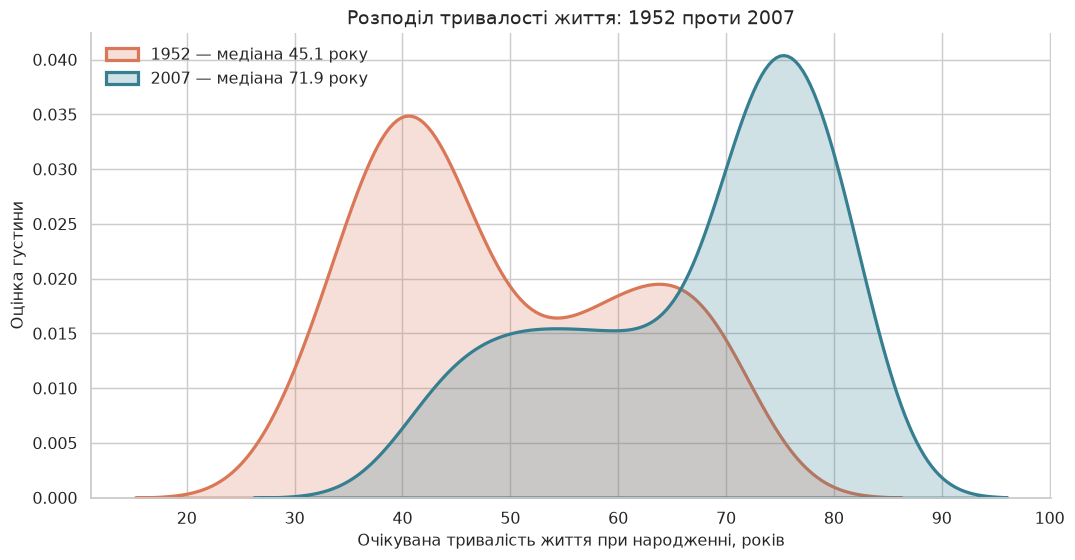

In [7]:
fig, ax = plt.subplots(figsize=(10.4,5.5))
for year,color in [(1952,"#d97757"),(2007,"#367f91")]:
    part=df[df.year==year]
    sns.kdeplot(data=part,x="lifeExp",ax=ax,fill=True,alpha=.23,
                color=color,linewidth=2.2,label=f"{year} — медіана {part.lifeExp.median():.1f} року")
ax.set(title="Розподіл тривалості життя: 1952 проти 2007",
       xlabel="Очікувана тривалість життя при народженні, років",
       ylabel="Оцінка густини")
ax.legend(frameon=False,loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "01_lifeexp_distribution.png", bbox_inches="tight")
plt.show()

**Висновок за розподілом:** середнє серед **142 країн** збільшилося з **49.1** року (1952) до **67.0** року (2007), тобто приблизно на **17.9 року**. Це **незважене середнє по країнах**, а не очікувана тривалість життя «середнього жителя планети». Розподіл у 2007 році зміщено праворуч, але між країнами все ще є відмінності.

## 6. Двовимірний EDA: фактори й цільова змінна

Для зв'язку доходу і `lifeExp` використовуємо **2007 рік окремо**, щоб не змішувати різні часові зрізи й повторні спостереження країн. `gdpPercap` показано на логарифмічній шкалі: однакова відстань по осі X означає однакову пропорційну зміну доходу. Кореляція Пірсона описує лінійний зв'язок між `lifeExp` та логарифмом ВВП, кореляція Спірмена — монотонний порядок без припущення лінійності.

2007: r Пірсона(log10 GDP, lifeExp)=0.809; ρ Спірмена(GDP, lifeExp)=0.857; n=142


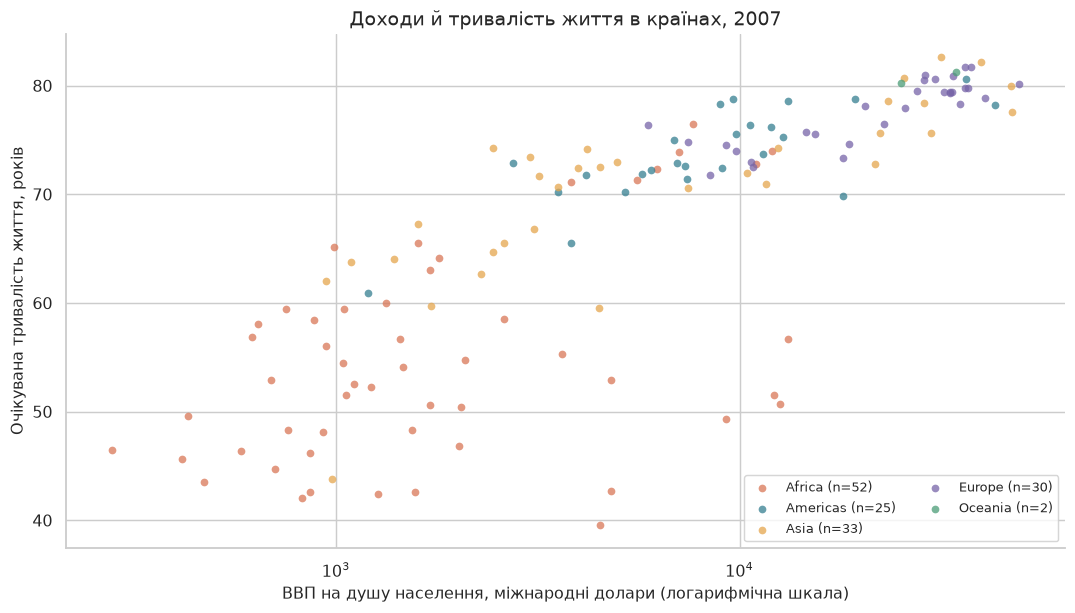

In [8]:
latest = df[df.year==2007].copy()
cor_pearson = latest["lifeExp"].corr(latest["log10_gdp_per_capita"])
cor_spearman = latest["lifeExp"].corr(latest["gdpPercap"],method="spearman")
print(f"2007: r Пірсона(log10 GDP, lifeExp)={cor_pearson:.3f}; "+
      f"ρ Спірмена(GDP, lifeExp)={cor_spearman:.3f}; n={len(latest)}")
fig, ax = plt.subplots(figsize=(10.4,6))
for cont,grp in latest.groupby('continent'):
    ax.scatter(grp.gdpPercap,grp.lifeExp,s=28,alpha=.75,label=f"{cont} (n={len(grp)})",
               color=PALETTE[cont],linewidths=0)
ax.set_xscale('log')
ax.set(title="Доходи й тривалість життя в країнах, 2007",
       xlabel="ВВП на душу населення, міжнародні долари (логарифмічна шкала)",
       ylabel="Очікувана тривалість життя, років")
ax.legend(frameon=True,ncol=2,loc='lower right',fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "02_gdp_life_scatter_2007.png",bbox_inches='tight')
plt.show()

**Висновок щодо зв'язку:** у 2007 році коефіцієнт Пірсона між `lifeExp` і **log10(ВВП на душу населення)** становить **r = 0.809** — сильна позитивна описова асоціація. Графік натякає на **нерівномірність приросту**: за великих доходів додаткова різниця в тривалості життя часто менша. Жодної причинної дії доходу цей графік не встановлює.

,n,mean_lifeExp,median_lifeExp,median_gdpPercap
continent,,,,
Africa,52,54.81,52.93,1452.27
Asia,33,70.73,72.40,4471.06
Americas,25,73.61,72.90,8948.10
Europe,30,77.65,78.61,28054.07
Oceania,2,80.72,80.72,29810.19


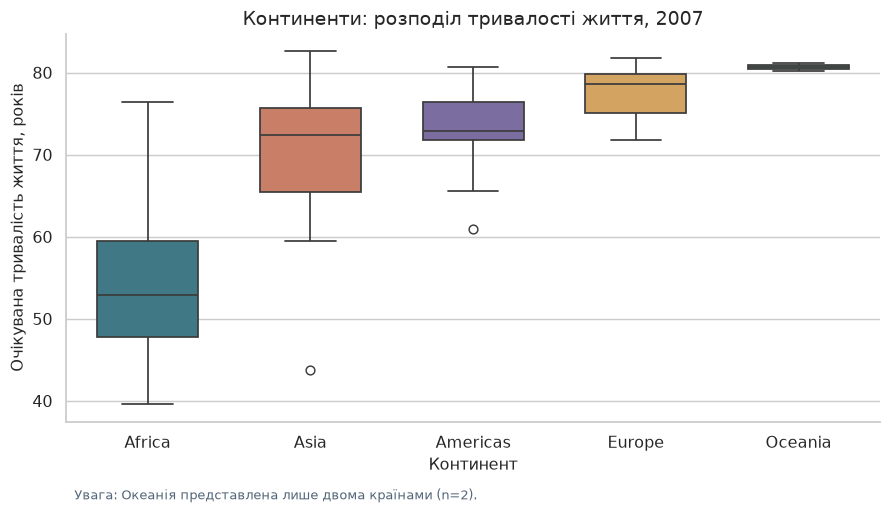

In [9]:
order=["Africa","Asia","Americas","Europe","Oceania"]
groups = (latest.groupby("continent")
          .agg(n=("lifeExp","size"),mean_lifeExp=("lifeExp","mean"),
               median_lifeExp=("lifeExp","median"),
               median_gdpPercap=("gdpPercap","median"))
          .reindex(order).round(2))
groups.to_csv(TABLE/"group_comparison_2007.csv")
display(groups)
fig,ax=plt.subplots(figsize=(10,5.6))
sns.boxplot(data=latest,x="continent",y="lifeExp",order=order,
            palette=[PALETTE[c] for c in order],ax=ax,width=.62,
            showfliers=True,linewidth=1.2,hue="continent",legend=False)
ax.set(title="Континенти: розподіл тривалості життя, 2007",
       xlabel="Континент", ylabel="Очікувана тривалість життя, років")
ax.text(.01,-.2,"Увага: Океанія представлена лише двома країнами (n=2).",
        transform=ax.transAxes,fontsize=9,color="#536679")
fig.subplots_adjust(bottom=.22)
fig.savefig(FIG / "03_continent_boxplot_2007.png",bbox_inches='tight')
plt.show()

**Висновок за континентами:** середнє `lifeExp` у 2007 році: Африка **54.8**, Азія **70.7**, Америка **73.6**, Європа **77.7**, Океанія **80.7** року. Групи мають суттєво різні розміри, зокрема **Океанія — лише 2 країни**, тому її оцінку не варто узагальнювати для всієї Океанії. Усередині континентів також існує значна неоднорідність.

## 7. Багатовимірний EDA: час, регіон, рівень доходу

Розглядаємо зміну `lifeExp` за період; кореляції між кількома **змістовними числовими показниками**; а також перевіряємо, чи зв'язок «дохід—тривалість життя» лишається у межах континентів у одному році. Під час порівняння років слід пам'ятати, що **це ті самі країни**, тож окремі записи не є незалежними спостереженнями.

,year,n_countries,mean_lifeExp,median_lifeExp,median_gdpPercap
0,1952,142,49.06,45.14,1968.53
1,1957,142,51.51,48.36,2173.22
2,1962,142,53.61,50.88,2335.44
3,1967,142,55.68,53.82,2678.33
4,1972,142,57.65,56.53,3339.13
5,1977,142,59.57,59.67,3798.61
6,1982,142,61.53,62.44,4216.23
7,1987,142,63.21,65.83,4280.30
8,1992,142,64.16,67.70,4386.09
9,1997,142,65.01,69.39,4781.83


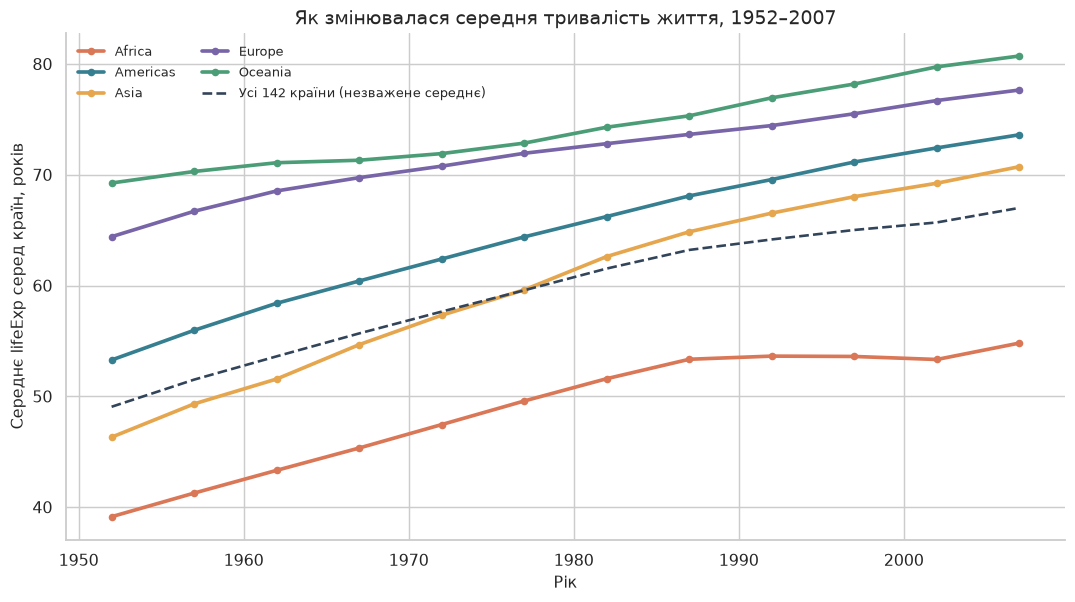

In [10]:
yearly = (df.groupby("year")
          .agg(n_countries=("country","nunique"),
               mean_lifeExp=("lifeExp","mean"),
               median_lifeExp=("lifeExp","median"),
               median_gdpPercap=("gdpPercap","median"))
          .reset_index())
yearly.to_csv(TABLE/"year_summary.csv",index=False)
continent_year = (df.groupby(["year","continent"])
                  .agg(n_countries=("country","nunique"),
                       mean_lifeExp=("lifeExp","mean"),
                       median_lifeExp=("lifeExp","median"))
                  .reset_index())
continent_year.to_csv(TABLE/"group_comparison.csv",index=False)
display(yearly.round(2))
fig,ax=plt.subplots(figsize=(10.4,5.9))
for cont,part in continent_year.groupby("continent"):
    ax.plot(part.year,part.mean_lifeExp,color=PALETTE[cont],lw=2.5,
            marker="o",markersize=4.2,label=cont)
ax.plot(yearly.year,yearly.mean_lifeExp,lw=1.8,ls='--',color='#32445a',
        label="Усі 142 країни (незважене середнє)")
ax.set(title="Як змінювалася середня тривалість життя, 1952–2007",
       xlabel="Рік",ylabel="Середнє lifeExp серед країн, років")
ax.legend(frameon=False,ncol=2,fontsize=9,loc='upper left')
fig.tight_layout()
fig.savefig(FIG/"04_trends_by_continent.png",bbox_inches='tight')
plt.show()

**Проміжний висновок:** усі континентальні середні у 2007 році вищі, ніж у 1952, але траєкторії різні. Лінії показують середнє **по країнах**, а не демографічно зважений показник для населення всього континенту.

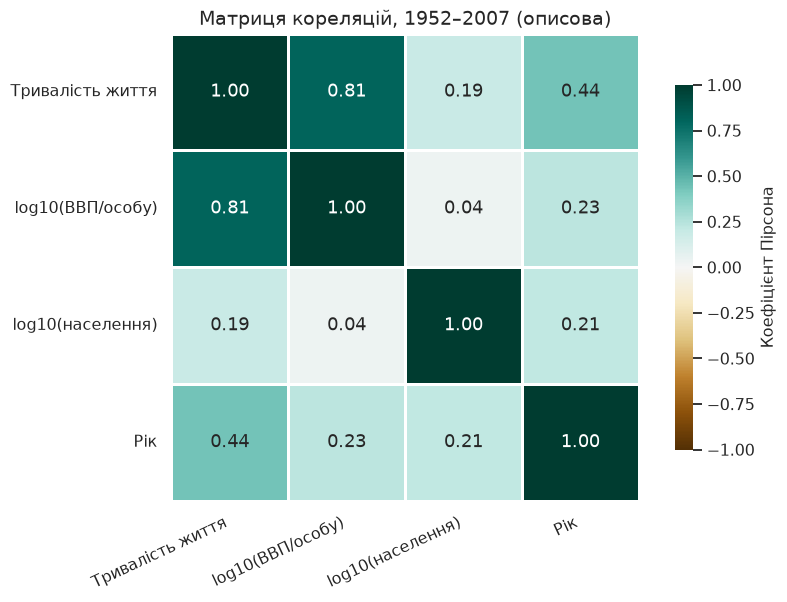

УВАГА: загальні кореляції змішують час і відмінності країн; не є незалежними вимірами.


In [11]:
corr_columns=["lifeExp","log10_gdp_per_capita","log10_population","year"]
corr_matrix=df[corr_columns].corr(method="pearson")
corr_matrix.to_csv(TABLE / "correlations.csv")
fig,ax=plt.subplots(figsize=(8.2,5.9))
labels=["Тривалість життя","log10(ВВП/особу)","log10(населення)","Рік"]
sns.heatmap(corr_matrix,annot=True,fmt='.2f',cmap='BrBG',center=0,vmin=-1,vmax=1,
            linewidths=1, square=True,ax=ax,xticklabels=labels,yticklabels=labels,
            cbar_kws={'shrink':.78,'label':'Коефіцієнт Пірсона'})
ax.set(title="Матриця кореляцій, 1952–2007 (описова)")
plt.xticks(rotation=25,ha='right');plt.yticks(rotation=0)
fig.tight_layout()
fig.savefig(FIG/"05_correlation_heatmap.png",bbox_inches='tight')
plt.show()
print("УВАГА: загальні кореляції змішують час і відмінності країн; не є незалежними вимірами.")

In [12]:
within_year = (df.groupby("year")
               .apply(lambda a: pd.Series({"n":len(a),
                   "pearson_log_gdp_life":a.lifeExp.corr(a.log10_gdp_per_capita),
                   "spearman_gdp_life":a.lifeExp.corr(a.gdpPercap,method='spearman')}),
                      include_groups=False)
               .reset_index())
within_year.to_csv(TABLE/"within_year_correlations.csv",index=False)
within_continent=[]
for continent_name,group in latest.groupby('continent'):
    within_continent.append({
      "continent":continent_name,"n":len(group),
      "pearson_log_gdp_life": group.lifeExp.corr(group.log10_gdp_per_capita) if len(group)>=5 else np.nan,
      "spearman_gdp_life": group.lifeExp.corr(group.gdpPercap,method='spearman') if len(group)>=5 else np.nan
    })
within_continent=pd.DataFrame(within_continent)
within_continent.to_csv(TABLE/"within_continent_correlations_2007.csv",index=False)
print("Зв'язок по роках:")
display(within_year.round(3))
print("Зв'язок у межах континентів (2007):")
display(within_continent.round(3))

Зв'язок по роках:


,year,n,pearson_log_gdp_life,spearman_gdp_life
0,1952,142.0,0.748,0.769
1,1957,142.0,0.759,0.782
2,1962,142.0,0.771,0.797
3,1967,142.0,0.773,0.795
4,1972,142.0,0.789,0.807
5,1977,142.0,0.814,0.828
6,1982,142.0,0.846,0.861
7,1987,142.0,0.874,0.892
8,1992,142.0,0.856,0.897
9,1997,142.0,0.864,0.895


Зв'язок у межах континентів (2007):


,continent,n,pearson_log_gdp_life,spearman_gdp_life
0,Africa,52,0.452,0.391
1,Americas,25,0.780,0.694
2,Asia,33,0.800,0.836
3,Europe,30,0.836,0.797
4,Oceania,2,NaN,NaN


**Інтерпретація багатовимірності:** загальна кореляція може бути частково пов'язана з одночасними змінами в часі та відмінностями регіонів. Окремі кореляції для 2007 року і всередині континентів зменшують таке змішування, хоча повністю **не контролюють конфаундери**. Для Океанії за `n=2` коефіцієнти свідомо не інтерпретуємо.

,continent,income_tercile,n,median_lifeExp
0,Africa,Низький,37,52.2950
1,Africa,Середній,11,71.1640
2,Africa,Високий,4,54.1570
3,Americas,Низький,1,60.9160
4,Americas,Середній,17,72.5670
5,Americas,Високий,7,78.2420
6,Asia,Низький,10,63.9235
7,Asia,Середній,11,71.9930
8,Asia,Високий,12,77.9940
9,Europe,Середній,7,74.0020


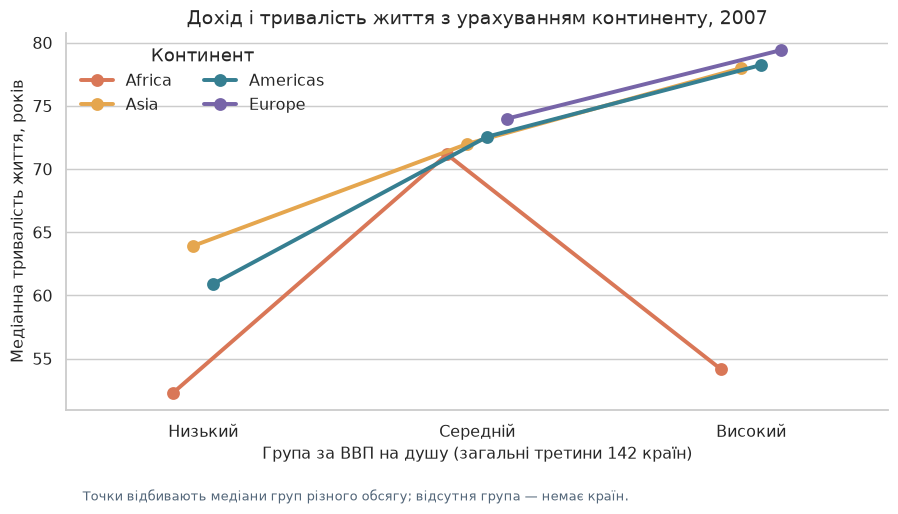

In [13]:
# Медіана lifeExp для третин доходу (у 2007 році) за континентом;
# межі третин обчислені один раз для всіх 142 країн.
latest=latest.copy()
latest["income_tercile"]=pd.qcut(latest.gdpPercap,3,labels=["Низький","Середній","Високий"])
tiers=(latest.groupby(["continent","income_tercile"],observed=True)
       .agg(n=("lifeExp","size"),median_lifeExp=("lifeExp","median"))
       .reset_index())
tiers.to_csv(TABLE/"income_terciles_2007.csv",index=False)
display(tiers)
fig,ax=plt.subplots(figsize=(10.1,5.7))
show=["Africa","Asia","Americas","Europe"]
sns.pointplot(data=tiers[tiers.continent.isin(show)],x="income_tercile",
              y="median_lifeExp",hue="continent",hue_order=show,
              palette=PALETTE,markers="o",dodge=.22,linestyles="-",ax=ax)
ax.set(title="Дохід і тривалість життя з урахуванням континенту, 2007",
       xlabel="Група за ВВП на душу (загальні третини 142 країн)",
       ylabel="Медіанна тривалість життя, років")
ax.legend(title="Континент",frameon=False,ncol=2)
ax.text(.02,-.24,"Точки відбивають медіани груп різного обсягу; відсутня група — немає країн.",
        transform=ax.transAxes,fontsize=8.7,color='#536679')
fig.subplots_adjust(bottom=.25)
fig.savefig(FIG / "06_income_terciles_continents.png",bbox_inches='tight')
plt.show()

Цей графік порівнює **узагальнені медіани**, а не індивідуальні траєкторії. В окремих клітинках мало країн, а поділ на третини доходів змінює точність порівняння — тому цей етап показує закономірності, але **не причинний ефект**.

## 8. Зміни окремих країн між 1952 і 2007 роками

Щоб не приховати різноспрямовану динаміку середніми значеннями, порівняємо **ті самі країни** в першому й останньому роках. Для цього обчислюємо `lifeExp(2007) − lifeExp(1952)` — зміна в **роках**, а не відсотках.

Медіанна зміна країни: 18.39 року
Частка країн зі зростанням: 98.6 %
Топ-5 зростань:


,country,lifeExp_1952,lifeExp_2007,change_years
141,Oman,37.578,75.640,38.062
140,Vietnam,40.412,74.249,33.837
139,Indonesia,37.468,70.650,33.182
138,Saudi Arabia,39.875,72.777,32.902
137,Libya,42.723,73.952,31.229


Топ-5 найменших змін:


,country,lifeExp_1952,lifeExp_2007,change_years
0,Zimbabwe,48.451,43.487,-4.964
1,Swaziland,41.407,39.613,-1.794
2,Zambia,42.038,42.384,0.346
3,Lesotho,42.138,42.592,0.454
4,Botswana,47.622,50.728,3.106


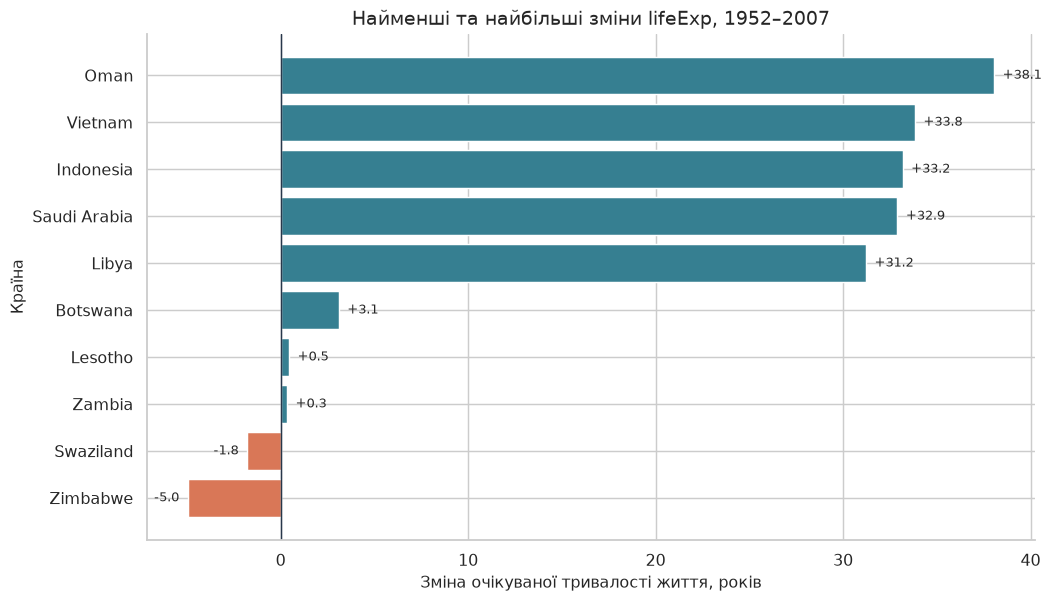

In [14]:
pivot=df.pivot(index="country",columns="year",values="lifeExp")
changes=(pivot[2007]-pivot[1952]).rename("change_years").sort_values()
country_changes=(pd.DataFrame({"country":changes.index,
                               "lifeExp_1952":pivot.loc[changes.index,1952].values,
                               "lifeExp_2007":pivot.loc[changes.index,2007].values,
                               "change_years":changes.values}))
country_changes.to_csv(TABLE/"country_changes.csv",index=False)
print("Медіанна зміна країни:", round(changes.median(),2),"року")
print("Частка країн зі зростанням:",round(100*(changes>0).mean(),1),"%")
print("Топ-5 зростань:")
display(country_changes.nlargest(5,'change_years'))
print("Топ-5 найменших змін:")
display(country_changes.nsmallest(5,'change_years'))
chart=pd.concat([changes.head(5),changes.tail(5)]).sort_values()
fig,ax=plt.subplots(figsize=(10.2,5.9))
bar_colors=['#d97757' if x<0 else '#367f91' for x in chart]
ax.barh(chart.index,chart.values,color=bar_colors)
ax.axvline(0,color='#28384b',lw=1)
ax.set(title="Найменші та найбільші зміни lifeExp, 1952–2007",
       xlabel="Зміна очікуваної тривалості життя, років",ylabel="Країна")
for i,val in enumerate(chart): ax.text(val+(0.45 if val>=0 else -.45),i,f"{val:+.1f}",
                                      va='center',ha='left' if val>=0 else 'right',fontsize=9)
fig.tight_layout()
fig.savefig(FIG/"07_country_changes.png",bbox_inches='tight')
plt.show()

**Проміжний висновок:** медіанний приріст для однієї країни — **18.4 року**, але розкид великий: від **-5.0** до **+38.1 року**. Зокрема, показник у Зімбабве за цим датасетом **знизився на 5.0 року**. Загальне покращення не означає однаковий результат для кожної країни.

## 9. Узагальнення результатів за дослідницькими запитаннями

1. **Зміни у часі:** незважене середнє по країнах суттєво зросло між 1952 і 2007 роками. Це характеризує набір країн, а не глобальний демографічний показник.
2. **Доходи й тривалість життя:** у зрізі 2007 року спостерігається сильний позитивний зв'язок між логарифмом ВВП на душу населення й очікуваною тривалістю життя; його не можна трактувати як доведений причинний вплив.
3. **Континентальні відмінності:** розподіли різняться, але існують і відмінності всередині континентів; Океанія має лише дві країни.
4. **Спільні закономірності:** зв'язок відрізняється залежно від року й континенту. Висновки з загальної матриці кореляцій мають враховувати змішування за часом/географією.
5. **Прогрес країн:** значення в більшості країн зросли, але темпи та напрями змін не всюди однакові.

### Обмеження і що можна робити далі

- Дані історичні (закінчуються 2007 роком), тому висновки **не описують сучасний стан**.
- Країни в наборі є неповною вибіркою світу; багаточисельні країни **не мають більшої ваги** у середніх по країнах.
- Багаторічні записи однієї країни статистично залежні; значення не є незалежною випадковою вибіркою.
- Кореляції не розкривають причин і можуть відображати фактори, яких немає в даних (медицина, освіта, інституції, конфлікти).
- Дані Gapminder — збірка з різних первинних статистичних джерел; історичні оцінки мають методологічну невизначеність.

**Наступний можливий крок** після цієї лабораторної — поглиблений аналіз із додатковими факторами; **регресійні моделі тут свідомо не навчалися**.

## 10. Збереження результатів, відтворюваність, джерела

- Очищена таблиця: `data/processed/clean_data.csv`.
- Таблиці: `outputs/tables/*.csv`.
- Графіки: `outputs/figures/*.png`.
- Опис перетворень та версії: `outputs/metadata/`.
- Презентація `reports/Presentation.pptx` готується на основі **тих самих експортованих таблиць і графіків**, а не переписаних вручну показників.

**Джерела:**
1. Gapminder — https://www.gapminder.org/data/  
2. Jennifer Bryan, R-пакет `gapminder` (CC0) — https://cran.r-project.org/package=gapminder  
3. Plotly Express — вбудований набір `px.data.gapminder()` — https://plotly.com/python/px-arguments/  
4. Gapminder dataset documentation — https://cran.r-project.org/web/packages/gapminder/gapminder.pdf

In [15]:
metadata={
 "title":"Lab02 — EDA of Gapminder life expectancy (1952–2007)",
 "source_url":"https://www.gapminder.org/data/",
 "dataset_package":"https://cran.r-project.org/package=gapminder",
 "license_note":"R gapminder dataset excerpt is documented as CC0; cite Gapminder",
 "source_in_archive":"data/raw/gapminder.csv",
 "target":"lifeExp (years at birth)",
 "unit_of_observation":"country-year",
 "rows_before":len(raw_df), "rows_after":len(df),
 "missing_before":int(raw_df.isna().sum().sum()),
 "duplicates_country_year":int(raw_df.duplicated(['country','year']).sum()),
 "cleaning":"No rows removed. Added log10_gdp_per_capita and log10_population for EDA.",
 "versions":{"python":platform.python_version(),"pandas":pd.__version__,
             "numpy":np.__version__, "matplotlib":plt.matplotlib.__version__,
             "seaborn":sns.__version__}
}
(META/"data_provenance_and_processing.json").write_text(
    json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf8')
print("Файли результатів:")
for folder in (BASE/"data"/"processed",TABLE,FIG,META):
    print(folder.relative_to(BASE),':',len(list(folder.iterdir())),"файлів")

Файли результатів:
data\processed : 1 файлів
outputs\tables : 12 файлів
outputs\figures : 7 файлів
outputs\metadata : 2 файлів
